In [1]:
!pip install torch torchvision torchaudio transformers[torch] --index-url https://download.pytorch.org/whl/rocm6.4

Looking in indexes: https://download.pytorch.org/whl/rocm6.4


In [2]:
!pip install evaluate scikit-learn

In [2]:
import pandas as pd
import numpy as np
import torch
from datasets import Dataset
from transformers import (
    DistilBertTokenizerFast,
    DistilBertForSequenceClassification,
    Trainer,
    TrainingArguments,
    EarlyStoppingCallback,
    set_seed,
)
import evaluate
from sklearn.model_selection import StratifiedKFold, train_test_split

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
set_seed(42)

print(f"Using device: {device}")

df = pd.read_csv("domain_dataset.csv")
df = df.rename(columns={'name': 'domain', 'malicious': 'label'})
df['label'] = df['label'].astype(int)
df, _ = train_test_split(
    df,
    train_size=500_000,
    stratify=df["label"],
    random_state=42,
)
df = df.sample(frac=1, random_state=42).reset_index(drop=True)  # shuffle

tokenizer = DistilBertTokenizerFast.from_pretrained("distilbert-base-uncased")

def tokenize_function(example):
    return tokenizer(example["domain"], padding="max_length", truncation=True, max_length=24)

accuracy = evaluate.load("accuracy")
precision = evaluate.load("precision")
recall = evaluate.load("recall")
f1 = evaluate.load("f1")

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=1)
    return {
        "accuracy": accuracy.compute(predictions=preds, references=labels)["accuracy"],
        "precision": precision.compute(predictions=preds, references=labels, average="binary")["precision"],
        "recall": recall.compute(predictions=preds, references=labels, average="binary")["recall"],
        "f1": f1.compute(predictions=preds, references=labels, average="binary")["f1"],
    }

kfold = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

for fold, (train_idx, val_idx) in enumerate(kfold.split(df['domain'], df['label'])):
    print(f"\n🚀 Fold {fold+1}/5")

    train_df = df.iloc[train_idx]
    val_df = df.iloc[val_idx]

    train_dataset = Dataset.from_pandas(train_df)
    val_dataset = Dataset.from_pandas(val_df)

    train_dataset = train_dataset.map(tokenize_function, batched=True)
    val_dataset = val_dataset.map(tokenize_function, batched=True)

    train_dataset.set_format(type="torch", columns=["input_ids", "attention_mask", "label"])
    val_dataset.set_format(type="torch", columns=["input_ids", "attention_mask", "label"])

    model = DistilBertForSequenceClassification.from_pretrained("distilbert-base-uncased", num_labels=2).to(device)

    training_args = TrainingArguments(
        output_dir=f"./results/fold_{fold}",
        num_train_epochs=10,
        bf16=True,
        per_device_train_batch_size=128,
        per_device_eval_batch_size=64,
        eval_strategy="epoch",
        save_strategy="epoch",
        logging_dir=f"./logs/fold_{fold}",
        logging_steps=10,
        load_best_model_at_end=True,
        metric_for_best_model="f1",
        greater_is_better=True,
        save_total_limit=1,
        seed=42,
        learning_rate=5e-5,
        warmup_ratio=0.1,
        weight_decay=0.01,
    )

    trainer = Trainer(
        model=model,
        args=training_args,
        train_dataset=train_dataset,
        eval_dataset=val_dataset,
        compute_metrics=compute_metrics,
        callbacks=[EarlyStoppingCallback(early_stopping_patience=2)],
    )

    trainer.train()

    results = trainer.evaluate()
    print(f"📈 Fold {fold+1} Results:", results)


/home/matheus/Documentos/Sync/Artigo/DistilBERT-X-CharLSTM/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/opt/amdgpu/share/libdrm/amdgpu.ids: No such file or directory


KeyboardInterrupt: 

In [15]:
trainer.save_model("./best_model_fold4")
tokenizer.save_pretrained("./best_model_fold4")

Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  6.96it/s]


('./best_model_fold4/tokenizer_config.json',
 './best_model_fold4/tokenizer.json')

In [7]:
# ==========================================
# Full training of DistilBERT and evaluation
# ==========================================

import json

import numpy as np
import pandas as pd
import torch
import evaluate

from datasets import Dataset
from sklearn.model_selection import train_test_split

from transformers import (
    DistilBertTokenizerFast,
    DistilBertForSequenceClassification,
    Trainer,
    TrainingArguments,
    EarlyStoppingCallback,
    set_seed,
)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
set_seed(42)

# Loading dataset
print(f"Using device: {device}")
df = pd.read_csv("domain_dataset.csv")
df = df.rename(columns={
    "name": "domain",
    "malicious": "label"
})
df["label"] = df["label"].astype(int)

# Split dataset
train_df, test_val_df = train_test_split(
    df,
    test_size=0.20,
    stratify=df["label"],
    random_state=42,
)

val_df, test_df = train_test_split(
    test_val_df,
    test_size=0.50,
    stratify=test_val_df["label"],
    random_state=42,
)

print(f"Training samples:   {len(train_df):,}")
print(f"Validation samples: {len(val_df):,}")
print(f"Test samples:       {len(test_df):,}")

# Load the tokenizer
tokenizer = DistilBertTokenizerFast.from_pretrained("distilbert-base-uncased")

def tokenize_function(example):
    return tokenizer(
        example["domain"],
        truncation=True,
        padding="max_length",
        max_length=24, # testing showed that the 99th percentile of length is 17, so 24 for good measure.
    )

# Convert dataset
train_dataset = Dataset.from_pandas(
    train_df,
    preserve_index=False
)

val_dataset = Dataset.from_pandas(
    val_df,
    preserve_index=False
)

test_dataset = Dataset.from_pandas(
    test_df,
    preserve_index=False
)

# Tokenize
train_dataset = train_dataset.map(
    tokenize_function,
    batched=True
)

val_dataset = val_dataset.map(
    tokenize_function,
    batched=True
)

test_dataset = test_dataset.map(
    tokenize_function,
    batched=True
)

# Set tensor format
columns = [
    "input_ids",
    "attention_mask",
    "label",
]

train_dataset.set_format(
    type="torch",
    columns=columns,
)

val_dataset.set_format(
    type="torch",
    columns=columns,
)

test_dataset.set_format(
    type="torch",
    columns=columns,
)

# Load model
model = DistilBertForSequenceClassification.from_pretrained(
    "distilbert-base-uncased",
    num_labels=2,
).to(device)

# Measure model parameter memory
model_memory = sum(
    p.numel() * p.element_size()
    for p in model.parameters()
) / (1024 ** 2)

print(f"Model parameter memory: {model_memory:.2f} MB")

# Define metrics
accuracy = evaluate.load("accuracy")
precision = evaluate.load("precision")
recall = evaluate.load("recall")
f1 = evaluate.load("f1")

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=1)

    return {
        "accuracy": accuracy.compute(predictions=preds, references=labels)["accuracy"],
        "precision": precision.compute(predictions=preds, references=labels, average="binary")["precision"],
        "recall": recall.compute(predictions=preds, references=labels, average="binary")["recall"],
        "f1": f1.compute(predictions=preds, references=labels, average="binary")["f1"],
    }


# Training arguments
training_args = TrainingArguments(
    output_dir="./results/final_model",

    num_train_epochs=10,

    learning_rate=5e-5,
    warmup_ratio=0.1,
    weight_decay=0.01,

    bf16=True,

    per_device_train_batch_size=128,
    per_device_eval_batch_size=128,

    eval_strategy="epoch",
    save_strategy="epoch",

    load_best_model_at_end=True,
    metric_for_best_model="f1",
    greater_is_better=True,

    save_total_limit=1,

    logging_dir="./logs/final_model",
    logging_steps=100,

    seed=42,
)

# Define trainer
trainer = Trainer(
    model=model,
    args=training_args,

    train_dataset=train_dataset,
    eval_dataset=val_dataset,

    compute_metrics=compute_metrics,

    callbacks=[
        EarlyStoppingCallback(
            early_stopping_patience=2
        )
    ],
)

# Train the thing
trainer.train()

# and save
trainer.save_model("./best_distilbert")

tokenizer.save_pretrained("./best_distilbert")


Using device: cuda
Training samples:   993,739
Validation samples: 124,217
Test samples:       124,218


Loading weights: 100%|██████████| 100/100 [00:00<00:00, 4318.10it/s]
[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.weight | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
classifier.bias         | MISSING    | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Model parameter memory: 255.41 MB


[transformers] warmup_ratio is deprecated and will be removed in v5.2. Use `warmup_steps` instead.
[transformers] `logging_dir` is deprecated and will be removed in v5.2. Please set `TENSORBOARD_LOGGING_DIR` instead.
/home/matheus/Documentos/Sync/Artigo/DistilBERT-X-CharLSTM/.venv/lib/python3.14/site-packages/transformers/integrations/sdpa_attention.py:154: UserWarning: Mem Efficient attention on Current AMD GPU is still experimental. Enable it with TORCH_ROCM_AOTRITON_ENABLE_EXPERIMENTAL=1. (Triggered internally at /pytorch/aten/src/ATen/native/transformers/hip/sdp_utils.cpp:338.)
  attn_output = torch.nn.functional.scaled_dot_product_attention(


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,0.360769,0.350804,0.832028,0.869356,0.781494,0.823087
2,0.326176,0.334687,0.839539,0.883056,0.782733,0.829874
3,0.283326,0.344255,0.840964,0.877458,0.792619,0.832884
4,0.234530,0.393293,0.839837,0.871338,0.797417,0.832741
5,0.183396,0.452539,0.835353,0.862819,0.797498,0.828874


Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  4.78it/s]


('./best_distilbert/tokenizer_config.json', './best_distilbert/tokenizer.json')

In [8]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
)
torch.cuda.reset_peak_memory_stats()

# Evaluate full DistilBERT training
predictions = trainer.predict(test_dataset)

peak_allocated = torch.cuda.max_memory_allocated() / (1024 ** 2)
print(f"Peak allocated memory during inference: {peak_allocated}")

logits = predictions.predictions
labels = predictions.label_ids

# Predicted probabilities for the positive class
probs = torch.softmax(torch.tensor(logits), dim=1)[:, 1].numpy()

# Predicted labels
preds = np.argmax(logits, axis=1)

results = {
    "accuracy": accuracy_score(labels, preds),
    "precision": precision_score(labels, preds),
    "recall": recall_score(labels, preds),
    "f1": f1_score(labels, preds),
    "roc_auc": roc_auc_score(labels, probs),
    "confusion_matrix": confusion_matrix(labels, preds).tolist(),
}

print(json.dumps(results, indent=4))

with open("bert_results_summary.json", "w") as f:
    json.dump(results, f, indent=4)



Peak allocated memory during inference: 1113.10888671875
{
    "accuracy": 0.8409087249834968,
    "precision": 0.8761569756080229,
    "recall": 0.794055611908097,
    "f1": 0.8330883967634588,
    "roc_auc": 0.9258478452200201,
    "confusion_matrix": [
        [
            55138,
            6971
        ],
        [
            12791,
            49318
        ]
    ]
}


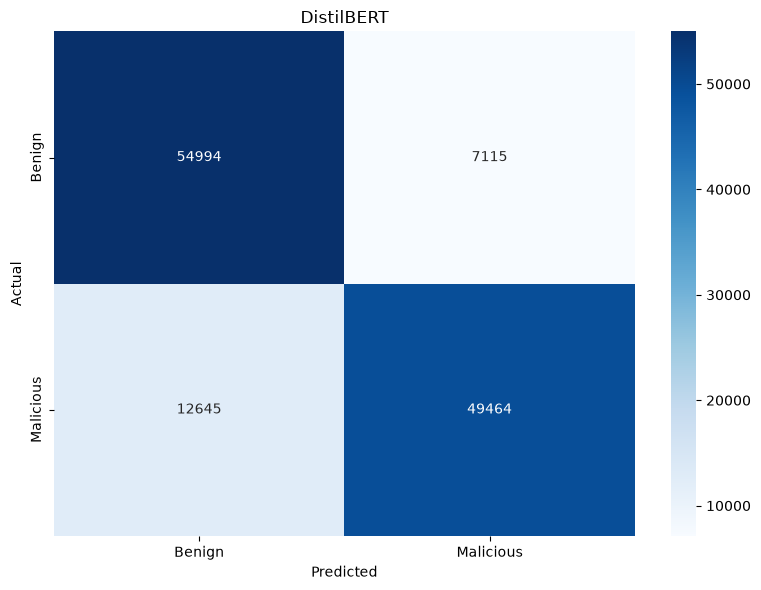

array([[54994,  7115],
       [12645, 49464]])

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
def plot_confusion_matrix(cm):
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=['Benign', 'Malicious'],
                yticklabels=['Benign', 'Malicious'])
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.title('DistilBERT')
    plt.tight_layout()
    plt.savefig('bert_confusion_matrix.png', dpi=1200, bbox_inches='tight')
    plt.show()

    return cm

plot_confusion_matrix(confusion_matrix(labels,preds))

0.9369647388823892
[0.5        0.50000805 0.50010468 ... 1.         1.         1.        ]
PR-AUC: 0.9370
Total predictions: 124218
Unique probabilities: 6096


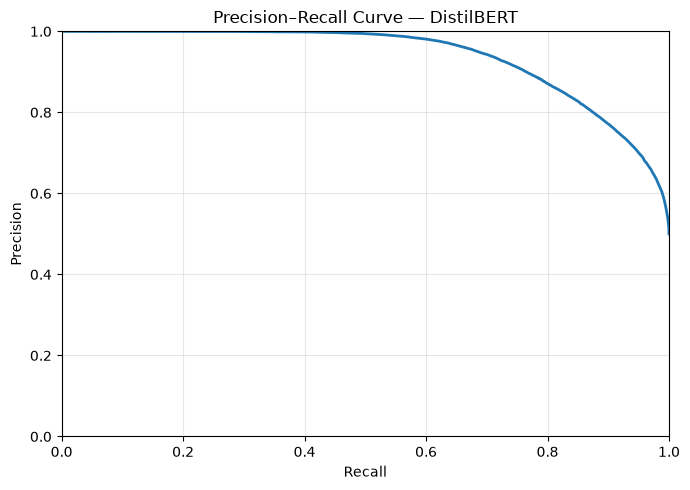

In [7]:
from sklearn.metrics import precision_recall_curve, average_precision_score, auc
import matplotlib.pyplot as plt
precision, recall, thresholds = precision_recall_curve(
    labels, probs
)

average_precision = average_precision_score(labels, probs)
print(average_precision)
print(precision)

pr_auc = auc(recall, precision)
print(f"PR-AUC: {pr_auc:.4f}")

print("Total predictions:", len(probs))
print("Unique probabilities:", len(np.unique(probs)))


plt.figure(figsize=(7, 5))

plt.plot(
    recall,
    precision,
    linewidth=2
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision–Recall Curve — DistilBERT")
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('bert_pr_curve.png', dpi=1200, bbox_inches='tight')
plt.show()

In [8]:
test_tokens = tokenizer.tokenize("google.com")
print(test_tokens)
print(len(test_tokens))
print(tokenizer.tokenize("google.com"))
print(tokenizer("google.com")["input_ids"])

['google', '.', 'com']
3
['google', '.', 'com']
[101, 8224, 1012, 4012, 102]
